# 03 · Model 2: alerts that mean the same thing

**Idea.** Model 1 only sees time. A message like "Absaugung 10 Unterdruck fehlt" says what went wrong, and the same kind of fault comes back on other days and other PLCs. Model 2 groups alerts by their text.

**How** (`src/central_logging/embeddings.py`, `text_clusters.py`)
1. **BERT** (`bert-base-uncased`): the CLS vector of each `alertText`, 768 numbers, in batches of 256. Loaded from a local cache, because the plant servers had no internet
2. **Autoencoder** 768 › 500 › 200 › 10 (the DEC step): density clustering does not work in 768 dimensions, so the encoder compresses each vector to 10. Trained with MSE, Adam (lr 0.001), 50 epochs, batches of 32. The scaler is fitted on the first PLC; the autoencoder is trained on the first PLC and then updated PLC by PLC instead of retrained
3. **HDBSCAN** (`min_cluster_size = 10`, `min_samples = 10`) on the 10-dimensional vectors. Some messages fire thousands of times and others a handful, and HDBSCAN handles clusters of different density. It is saved with `prediction_data`, so new days are labelled with `approximate_predict` instead of refitting

Here the model is trained on week 1 of the generated plant and applied to the daily files of week 2.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from central_logging import config, plotting
from central_logging.plotting import SERIES, MUTED, TEXT, TEXT_2

plotting.use_style()
pd.set_option("display.max_colwidth", 90)
RESULTS = ROOT / "results"
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
training = pd.read_csv(RESULTS / "autoencoder_training.csv")
print(f"Autoencoder trained on {len(training)} PLCs, {training.rows.sum():,} alerts of week 1")
training.round(4).head(8)

Autoencoder trained on 75 PLCs, 86,016 alerts of week 1


,plc_file,rows,first_epoch_loss,last_epoch_loss
0,A1FOE01,930,0.5523,0.0013
1,A1FOE02,3316,0.0101,0.0008
2,A1FOE03,2756,0.0017,0.0003
3,A1FTS01,18298,0.0010,0.0000
4,A1FTS02,404,0.5477,0.1103
5,A1KLB01,514,0.9997,0.0002
6,A1KLB02,956,0.2736,0.0003
7,A1KLB03,421,0.3783,0.0015


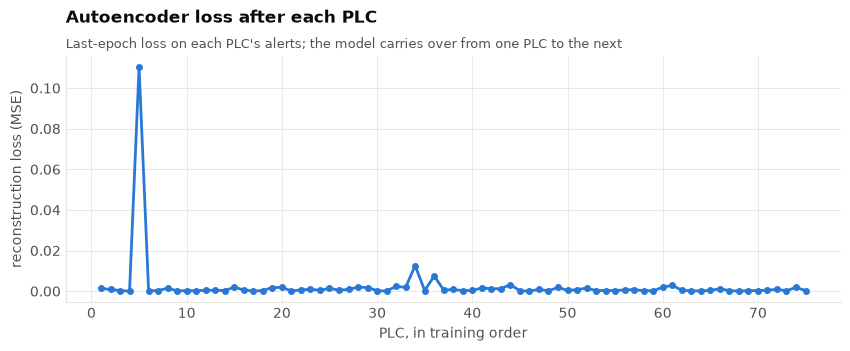

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(range(1, len(training) + 1), training.last_epoch_loss, color=SERIES[0], marker="o", ms=4)
ax.set_xlabel("PLC, in training order")
ax.set_ylabel("reconstruction loss (MSE)")
ax.set_title("Autoencoder loss after each PLC")
plotting.subtitle(ax, "Last-epoch loss on each PLC's alerts; the model carries over from one PLC to the next")
fig.savefig(FIG / "model2_autoencoder_loss.png")
plt.show()

## Running it
The week-2 results below come from `python -m central_logging.benchmark`. Set `RUN_TEXT_MODEL = True` to embed and encode a sample here (needs the BERT files; downloads them once if they are not cached).

In [4]:
RUN_TEXT_MODEL = False

if RUN_TEXT_MODEL:
    from central_logging.embeddings import TextEmbedder
    from central_logging.generate import generate
    from central_logging.text_clusters import train_text_model, TextClusterer

    alerts, truth, plant = generate(days=2)
    model_dir = ROOT / "notebooks" / "app_demo" / "text_model"
    embedder = TextEmbedder()
    sets = [(plc, embedder.embed(g.alertText.tolist())) for plc, g in alerts.groupby("alertPlc")]
    train_text_model(sets, model_dir, epochs=5)
    sample = alerts.sample(2000, random_state=0)
    sample["Text_Cluster"] = TextClusterer(model_dir).predict(embedder.embed(sample.alertText.tolist()))
    display(sample[["alertText", "Text_Cluster"]].head(10))

## Week 2: groups against the fault families

In [5]:
scores = json.loads((RESULTS / "scores_min_samples_7.json").read_text())["model2"]
pd.Series(scores).round(3).to_frame("week 2")

,week 2
alerts,86306.000
text_clusters,984.000
noise_share,0.065
distinct_texts,1781.000
ari,0.095
homogeneity,0.940
completeness,0.375


In [6]:
texts = pd.read_csv(RESULTS / "text_clusters_week2.csv")
labelled = texts[texts.Text_Cluster >= 0]
per_cluster = labelled.groupby("Text_Cluster").agg(messages=("alertText", "nunique"), families=("family", "nunique"))
summary = pd.Series({
    "groups": len(per_cluster),
    "groups with one message": int((per_cluster.messages == 1).sum()),
    "groups joining variants of a message": int((per_cluster.messages > 1).sum()),
    "groups mixing fault families": int((per_cluster.families > 1).sum()),
    "messages labelled noise (-1)": int((texts.Text_Cluster < 0).sum()),
})
summary.to_frame("count")

,count
groups,984
groups with one message,728
groups joining variants of a message,256
groups mixing fault families,0
messages labelled noise (-1),406


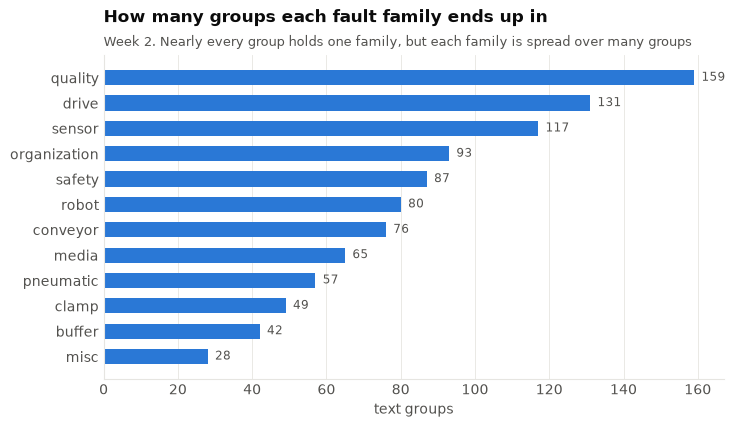

In [7]:
split = labelled.groupby("family").Text_Cluster.nunique().sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(split.index, split.values, color=SERIES[0], height=0.6)
for y, v in enumerate(split.values):
    ax.text(v + 2, y, str(v), va="center", fontsize=8.5, color=TEXT_2)
ax.set_xlabel("text groups")
ax.set_title("How many groups each fault family ends up in")
plotting.subtitle(ax, "Week 2. Nearly every group holds one family, but each family is spread over many groups")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "model2_groups_per_family.png")
plt.show()

Groups that join several messages, from three fault families. They collect the same fault with different device or station numbers.

In [8]:
multi = per_cluster[per_cluster.messages > 1].sort_values("messages", ascending=False)
family_of = labelled.groupby("Text_Cluster").family.first()
shown = []
for k in multi.index:                      # the widest group of three different families
    if family_of[k] not in shown and len(shown) < 3:
        shown.append(family_of[k])
        display(texts[texts.Text_Cluster == k][["Text_Cluster", "alertText", "family", "alerts"]].head(6))

,Text_Cluster,alertText,family,alerts
644,171,SY1 Uhrzeit 13 nicht synchron,misc,14
645,171,SY7 Uhrzeit 1 nicht synchron,misc,7
646,171,SY9 Uhrzeit 18 nicht synchron,misc,7
647,171,SY1 Uhrzeit 14 nicht synchron,misc,6
648,171,SY1 Uhrzeit 4 nicht synchron,misc,6
649,171,SY4 Uhrzeit 11 nicht synchron,misc,6


,Text_Cluster,alertText,family,alerts
1723,966,HT2 Hubtisch 15 Position oben fehlt,conveyor,480
1724,966,HT9 Hubtisch 8 Position oben fehlt,conveyor,246
1725,966,HT3 Hubtisch 4 Position oben fehlt,conveyor,183
1726,966,HT1 Hubtisch 16 Position oben fehlt,conveyor,160
1727,966,HT1 Hubtisch 7 Position oben fehlt,conveyor,139
1728,966,HT2 Hubtisch 6 Position oben fehlt,conveyor,122


,Text_Cluster,alertText,family,alerts
556,107,OR8 Typwechsel 20 laeuft,organization,109
557,107,OR8 Typwechsel 12 laeuft,organization,15
558,107,OR8 Typwechsel 8 laeuft,organization,11
559,107,OR8 Typwechsel 14 laeuft,organization,7
560,107,OR7 Typwechsel 18 laeuft,organization,2


## Takeaway
- Model 2 does not put different kinds of fault into one group (homogeneity 0.94). Where it joins messages, it joins variants of the same message: the same fault on a different valve or station.
- It is very fine-grained: about 1,000 groups for 12 fault families. Frequent messages get a group of their own, because identical texts sit on top of each other in the latent space.
- For Model 3 that is still useful: `Text_Cluster` tells it which alerts say the same thing, independent of when they fired.